# Поиск аномалий во временном ряду с помощью скользящего z-score

**Аннотация.** Рассматривается причинный скользящий z-score для обнаружения отклонений в одномерном временном ряду. Метод сравнивает текущее наблюдение со средним и стандартным отклонением предыдущего окна. На синтетических данных исследуются одиночные и соседние скачки, изменение уровня и разброса, дрейф, сезонность, зависание датчика и пропуски. Отдельно рассматриваются выбор порога, доступность оценки и связь с линейной регрессией.

**Цель:** определить, в каких условиях локальная стандартизация обнаруживает изменения и какие ограничения возникают при ошибках измерения и смене режима.

Эксперименты проводятся на искусственно сформированных рядах с условной разметкой. Результаты иллюстрируют поведение метода, но не являются оценкой качества на реальном оборудовании. Сигнал об отклонении не устанавливает причину события.

## 1. Исходные данные и постановка задачи

Рассматривается **один числовой показатель на каждый момент времени**, расположенный в хронологическом порядке, например почасовая температура датчика. Для разных датчиков и величин расчёт выполняется отдельно. Размер окна задаётся числом наблюдений, а не длительностью: при нерегулярных измерениях требуется выравнивание ряда либо использование временного окна.

| Поле | Пример | Назначение |
|---|---|---|
| `time` | `2025-01-01 10:00:00` | Упорядочивание и проверка шага ряда. |
| `value` | `21.4` или `NaN` | Значение измерения; бесконечности и нечисловые значения требуют отдельной обработки. |
| `label` | `True`, `False` или неизвестно | Условная метка для оценки качества; для расчёта z-score не требуется. |

Формула не устраняет дубликаты и пропуски временных меток, изменения единиц, замену датчика или смену режима. Причина отклонения определяется с учётом предметной области.

## 2. Скользящий z-score

Z-score представляет собой **знаковую числовую оценку каждого наблюдения**:

$$z_t = \frac{x_t-\mu_t}{\sigma_t}, \quad \mu_t,\sigma_t \text{ рассчитаны по } x_{t-w},\dots,x_{t-1}.$$

- `z = +3`: значение выше среднего на три стандартных отклонения.
- `z = -3`: значение ниже среднего на три стандартных отклонения.
- `z = 0`: значение совпадает со средним при определённом разбросе.
- `NaN`: оценка неопределённа; это не означает нормальное состояние.

Порог задаётся отдельно: например, `abs(z) > 3` формирует сигнал в обе стороны, тогда как `z > 3` учитывает только превышения. Использование модуля приводит к потере знака, поэтому исходные значения z сохраняются. Интервал `среднее ± 3σ` — визуальное представление порога, а не результат функции z-score.

В причинном скользящем варианте текущее наблюдение и будущие данные в расчёт его статистик не входят. Глобальный z-score, напротив, вычисляет общие статистики для всего массива; оба метода возвращают знаковые числа, но решают разные задачи. Стандартное отклонение в работе рассчитывается с `ddof=0`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import zscore
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error


def rolling_stats(values, window=24, min_std=1e-12):
    """Статистики строго предыдущих window измерений; index и NaN сохранены.

    Условие: числовой ряд по времени, NaN допустим; бесконечности отклоняются.
    min_std — технический допуск для практически постоянного окна в единицах ряда.
    """
    if not isinstance(window, int) or window < 2:
        raise ValueError('window должен быть целым числом >= 2')
    if not np.isfinite(min_std) or min_std < 0:
        raise ValueError('min_std должен быть конечным неотрицательным числом')
    s = pd.Series(values, dtype='float64').copy()
    if np.isinf(s.to_numpy()).any():
        raise ValueError('Бесконечность не является допустимым измерением')
    past = s.shift(1).rolling(window=window, min_periods=window)
    mean = past.mean()
    sigma = past.std(ddof=0)
    # Rolling std на постоянном окне иногда даёт шум округления; проверяем и сам диапазон.
    flat = (past.max() == past.min()) & past.max().notna()
    sigma = sigma.mask(flat, 0.0)
    # В нулевом/почти нулевом разбросе деление считаем неопределённым.
    z = (s - mean) / sigma.mask(sigma <= min_std)
    return pd.DataFrame({'value': s, 'past_mean': mean, 'past_std': sigma, 'z_score': z})


def rolling_z_score(values, window=24, min_std=1e-12):
    """Возвращает один знаковый z-score на входную точку, а не пороги/радиусы."""
    return rolling_stats(values, window, min_std)['z_score'].rename('z_score')


def signal_from_z(scores, threshold=3.0):
    """Булево решение отдельно от scores. Неопределённый score -> pd.NA."""
    if not np.isfinite(threshold) or threshold < 0:
        raise ValueError('threshold должен быть конечным неотрицательным числом')
    scores = pd.Series(scores, dtype='float64')
    signal = scores.abs().gt(threshold).astype('boolean')
    return signal.mask(scores.isna(), pd.NA).rename('signal')

# Пример из ручного расчёта и проверки контрактов.
s = pd.Series([8., 10., 12., 15., 5.])
local_z = rolling_z_score(s, window=3)
global_z = pd.Series(zscore(s.to_numpy(), ddof=0), name='global_z')
example = pd.DataFrame({'value': s, 'global_z (scipy)': global_z,
                        'rolling_z': local_z, 'сигнал |z| > 3': signal_from_z(local_z)})
display(example.round(3))
assert np.isclose(local_z.iloc[3], (15 - 10)/np.sqrt(8/3))
assert local_z.iloc[3] > 0 and local_z.iloc[4] < 0
assert local_z.iloc[:3].isna().all() and pd.isna(signal_from_z(local_z).iloc[0])
assert pd.isna(rolling_z_score([1, 1, 1, 8], 3).iloc[3])
assert pd.isna(rolling_z_score([20.5, 20.1] + [20.] * 26, 24).iloc[-1])
assert pd.isna(rolling_z_score([8, np.nan, 12, 15], 3).iloc[3])
assert np.isclose(rolling_z_score([8, 10, 12, 15, 999], 3).iloc[3], local_z.iloc[3])
print('Проверки формулы, знака, NaN, нулевого разброса и отсутствия будущего пройдены.')

,value,global_z (scipy),rolling_z,сигнал |z| > 3
0,8.0,-0.587,NaN,<NA>
1,10.0,0.000,NaN,<NA>
2,12.0,0.587,NaN,<NA>
3,15.0,1.468,3.062,True
4,5.0,-1.468,-3.569,True


Проверки формулы, знака, NaN, нулевого разброса и отсутствия будущего пройдены.


Для истории `[8, 10, 12]` среднее равно 10, стандартное отклонение — $\sqrt{8/3}\approx1{,}633$. Следующее значение 15 даёт **+3,062**. В следующем окне `[10, 12, 15]` значение 5 имеет отрицательный z-score. Первые три результата неопределённы из-за недостатка истории. Глобальный `scipy.stats.zscore` использует все пять точек, включая будущие, поэтому не является причинной онлайн-оценкой.

Z-score преобразует значения, но не исправляет и не удаляет измерения. Исключение или замена точек по полученным сигналам — отдельное решение, которое может привести к потере значимых событий.

## 3. Пропуски и нулевой разброс

В эксперименте применяется строгая политика: для оценки необходимы **все предыдущие `window` значений**. Пропуск в текущей точке даёт `NaN`; пока он находится в предыдущем окне, оценки следующих точек также неопределённы. После выхода пропуска из окна вычисление возобновляется. Неполное окно или заполнение пропусков возможны, но меняют статистику и требуют отдельной проверки.

В постоянном окне стандартное отклонение равно нулю и деление не определено. Нулевой и практически нулевой разброс (по умолчанию $10^{-12}$ в единицах ряда) приводят к неопределённой оценке. Для обнаружения зависшего датчика необходим дополнительный контроль постоянства. Бесконечные значения функция отклоняет; пропуски и состояние канала связи контролируются отдельно от z-score.

In [2]:
missing = pd.Series([8., 10., 12., np.nan, 15., 9., 11., 14.])
missing_table = rolling_stats(missing, 3)
missing_table['signal'] = signal_from_z(missing_table.z_score)
print('Политика: три предыдущих значения должны быть известны.')
display(missing_table.round(3))
print('Исходное число пропусков:', missing.isna().sum(),
      '; неопределённых score:', missing_table.z_score.isna().sum())
filled = missing.ffill()
comparison = pd.DataFrame({'исходное': missing, 'ffill': filled,
                           'z строгий': rolling_z_score(missing, 3),
                           'z после ffill': rolling_z_score(filled, 3)})
print('Что изменится, если без отдельной проверки протянуть прошлое значение:')
display(comparison.round(3))
print('Пропуск на шаге 3 при ffill выглядит как измерение:', filled.iloc[3])

Политика: три предыдущих значения должны быть известны.


,value,past_mean,past_std,z_score,signal
0,8.0,NaN,NaN,NaN,<NA>
1,10.0,NaN,NaN,NaN,<NA>
2,12.0,NaN,NaN,NaN,<NA>
3,NaN,10.000,1.633,NaN,<NA>
4,15.0,NaN,NaN,NaN,<NA>
5,9.0,NaN,NaN,NaN,<NA>
6,11.0,NaN,NaN,NaN,<NA>
7,14.0,11.667,2.494,0.935,False


Исходное число пропусков: 1 ; неопределённых score: 7
Что изменится, если без отдельной проверки протянуть прошлое значение:


,исходное,ffill,z строгий,z после ffill
0,8.0,8.0,NaN,NaN
1,10.0,10.0,NaN,NaN
2,12.0,12.0,NaN,NaN
3,NaN,12.0,NaN,1.225
4,15.0,15.0,NaN,3.889
5,9.0,9.0,NaN,-2.828
6,11.0,11.0,NaN,-0.408
7,14.0,14.0,0.935,0.935


Пропуск на шаге 3 при ffill выглядит как измерение: 12.0


В примере `ffill` используется для сравнения: перенос последнего значения скрывает пропуск и может изменить последующий разброс. Применимость заполнения зависит от предметной области. Удаление пропусков с помощью `dropna()` сокращает ряд: окно из 24 оставшихся строк не обязательно соответствует 24 часам. Интерполяция с использованием будущей точки не подходит для причинной оценки в реальном времени.

## 4. Данные эксперимента

Рассматриваются девять сценариев по 240 почасовых значений. Большинство используют одинаковую исходную последовательность со средним уровнем около 20 и нормальным шумом с $\sigma=0{,}4$; seed фиксирован. Общий фон позволяет сравнивать изменения при одинаковых условиях, но сценарии не являются независимыми повторами. Позиции нумеруются с нуля, диапазоны полуоткрытые: `[120, 190)` включает 120, но не 190.

| Сценарий | Изменение | Условная разметка |
|---|---|---|
| Контроль | Изменений нет | Размеченных аномалий нет. |
| Скачки | `+7` в 100, `−7` в 150 | Две точки. |
| Два рядом | `+12` в 100, `+5` в 102 | Две точки. |
| Сдвиг уровня | `+5` на `[120,190)` | Весь изменённый интервал. |
| Дрейф | `+0,08·(t−120+1)` на `[120,190)` | Интервал изменения. |
| Рост разброса | Дополнительный шум с σ=2 на `[120,190)` | Весь интервал повышенного шума. |
| Зависание | Постоянное значение 20 на `[120,190)` | Интервал зависания датчика. |
| Сезонность и контекст | Суточный цикл; в точке 150 значение противоположной фазы | Точка 150. |
| Пропуск | `NaN` на `[120,126)` | Метки пропущенных измерений неизвестны. |

Разметка интервалов условна: сдвиг или дрейф могут быть штатным изменением процесса. Интервальные метки используются для проверки точечного правила и не означают, что каждое значение интервала является отдельным выбросом.

In [3]:
N = 240
TIME = pd.date_range('2025-01-01', periods=N, freq='h')
t = np.arange(N)
rng = np.random.default_rng(17)
base = 20 + rng.normal(0, 0.4, N)
cases = {}

def add_case(name, values, labels):
    cases[name] = pd.DataFrame({'time': TIME, 'value': values,
                                'label': pd.array(labels, dtype='boolean')})

normal_labels = pd.array(np.zeros(N, dtype=bool), dtype='boolean')
add_case('Контроль', base.copy(), normal_labels.copy())
a = base.copy(); lab = normal_labels.copy(); a[100] += 7; a[150] -= 7; lab[[100, 150]] = True
add_case('Скачки', a, lab)
a = base.copy(); lab = normal_labels.copy(); a[100] += 12; a[102] += 5; lab[[100, 102]] = True
add_case('Два рядом', a, lab)
a = base.copy(); lab = normal_labels.copy(); a[120:190] += 5; lab[120:190] = True
add_case('Сдвиг уровня', a, lab)
a = base.copy(); lab = normal_labels.copy(); a[120:190] += 0.08*np.arange(1, 71); lab[120:190] = True
add_case('Дрейф', a, lab)
a = base.copy(); lab = normal_labels.copy(); a[120:190] += rng.normal(0, 2, 70); lab[120:190] = True
add_case('Рост разброса', a, lab)
a = base.copy(); lab = normal_labels.copy(); a[120:190] = 20; lab[120:190] = True
add_case('Зависание', a, lab)
a = 20 + 3*np.sin(2*np.pi*t/24) + rng.normal(0, 0.25, N)
lab = normal_labels.copy(); a[150] = 20 + 3*np.sin(2*np.pi*(150+12)/24); lab[150] = True
add_case('Контекстная', a, lab)
a = base.copy(); lab = normal_labels.copy(); a[120:126] = np.nan; lab[120:126] = pd.NA
add_case('Пропуск', a, lab)

# Файл формируется ноутбуком: пригоден для просмотра и скачивания в Colab.
data = pd.concat([df.assign(scenario=name, step=np.arange(N)) for name, df in cases.items()], ignore_index=True)
data = data[['scenario', 'step', 'time', 'value', 'label']]
data.to_csv('z_score_demo_data.csv', index=False)
print('Сценариев:', len(cases), '; строк всего:', len(data))
print('Файл для скачивания: z_score_demo_data.csv')
display(data.groupby('scenario').agg(rows=('value', 'size'), missing=('value', lambda x: int(x.isna().sum())),
                                     positive_labels=('label', lambda x: int(x.fillna(False).sum()))))
print('Пример исходных строк около пропуска:')
display(data[(data.scenario == 'Пропуск') & data.step.between(118, 128)].reset_index(drop=True))

Сценариев: 9 ; строк всего: 2160
Файл для скачивания: z_score_demo_data.csv


,rows,missing,positive_labels
scenario,,,
Два рядом,240,0,2
Дрейф,240,0,70
Зависание,240,0,70
Контекстная,240,0,1
Контроль,240,0,0
Пропуск,240,6,0
Рост разброса,240,0,70
Сдвиг уровня,240,0,70
Скачки,240,0,2


Пример исходных строк около пропуска:


,scenario,step,time,value,label
0,Пропуск,118,2025-01-05 22:00:00,20.088853,False
1,Пропуск,119,2025-01-05 23:00:00,19.889222,False
2,Пропуск,120,2025-01-06 00:00:00,NaN,<NA>
3,Пропуск,121,2025-01-06 01:00:00,NaN,<NA>
4,Пропуск,122,2025-01-06 02:00:00,NaN,<NA>
5,Пропуск,123,2025-01-06 03:00:00,NaN,<NA>
6,Пропуск,124,2025-01-06 04:00:00,NaN,<NA>
7,Пропуск,125,2025-01-06 05:00:00,NaN,<NA>
8,Пропуск,126,2025-01-06 06:00:00,19.810707,False
9,Пропуск,127,2025-01-06 07:00:00,20.425979,False


## 5. Результаты для различных типов событий

Для всех сценариев зафиксированы `window=24` и `threshold=3`. Цель опыта — исследование поведения одной настройки, а не выбор оптимального детектора. Знаковые z-score и сигналы рассчитываются отдельно. На графиках показаны исходные значения и оценки; размеченные точки отмечены красным, пропуски — серым.

Обозначения в таблице:
- `оценено` — количество определённых z-score; `неизвестно` включает разогрев, пропуски и нулевой разброс;
- `TP` — размеченная аномалия с сигналом, `FP` — сигнал на размеченной норме, `FN` — размеченная аномалия без сигнала; расчёт ведётся только при известных оценке и метке;
- `precision оценённых` — доля TP среди сигналов на оценённых и размеченных точках;
- `пропущено из-за score` — число размеченных положительных точек с неопределённой оценкой;
- `recall оценённых` — доля обнаруженных аномалий среди положительных точек с определённым score, а не recall по всему ряду.

Для контроля и сценария с пропусками положительных меток нет, поэтому recall не определён. Для длительных интервалов отдельно рассматривается обнаружение события и задержка первого сигнала.

In [4]:
WINDOW, THRESHOLD = 24, 3.0

def evaluate_case(df, window=WINDOW, threshold=THRESHOLD):
    stats = rolling_stats(df['value'], window)
    score = stats.z_score
    signals = signal_from_z(score, threshold)
    labels = df.label.astype('boolean')
    known = score.notna() & labels.notna()
    pos = labels.fillna(False).astype(bool)
    predicted = signals.fillna(False).astype(bool)
    tp = int((known & pos & predicted).sum())
    fp = int((known & ~pos & predicted).sum())
    fn = int((known & pos & ~predicted).sum())
    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn) if tp + fn else np.nan
    return {'оценено': int(score.notna().sum()), 'неизвестно': int(score.isna().sum()),
            'размечено +': int(pos.sum()), 'TP': tp, 'FP': fp, 'FN': fn,
            'пропущено из-за score': int((pos & score.isna()).sum()),
            'precision оценённых': precision, 'recall оценённых': recall}, stats, signals

rows = []
for name, df in cases.items():
    row, _, _ = evaluate_case(df)
    rows.append({'сценарий': name, **row})
summary = pd.DataFrame(rows).set_index('сценарий')
display(summary.round(3))

,оценено,неизвестно,размечено +,TP,FP,FN,пропущено из-за score,precision оценённых,recall оценённых
сценарий,,,,,,,,,
Контроль,216,24,0,0,4,0,0,0.000,NaN
Скачки,216,24,2,2,3,0,0,0.400,1.000
Два рядом,216,24,2,1,3,1,0,0.250,0.500
Сдвиг уровня,216,24,70,3,6,67,0,0.333,0.043
Дрейф,216,24,70,0,6,70,0,0.000,0.000
Рост разброса,216,24,70,5,3,65,0,0.625,0.071
Зависание,169,71,70,0,5,24,46,0.000,0.000
Контекстная,216,24,1,0,0,1,0,NaN,0.000
Пропуск,186,54,0,0,3,0,0,0.000,NaN


На контрольном ряду получено 4 ложные тревоги среди 216 оценённых точек. Оба одиночных скачка обнаружены, тогда как в паре соседних скачков обнаружен только первый. При длительном сдвиге сигнал получили 3 из 70 точек; при медленном дрейфе сигналов внутри интервала не было. Для зависшего датчика 46 размеченных точек не получили определённой оценки. Контекстная аномалия не обнаружена по исходному ряду. Результаты относятся только к указанным данным и параметрам.

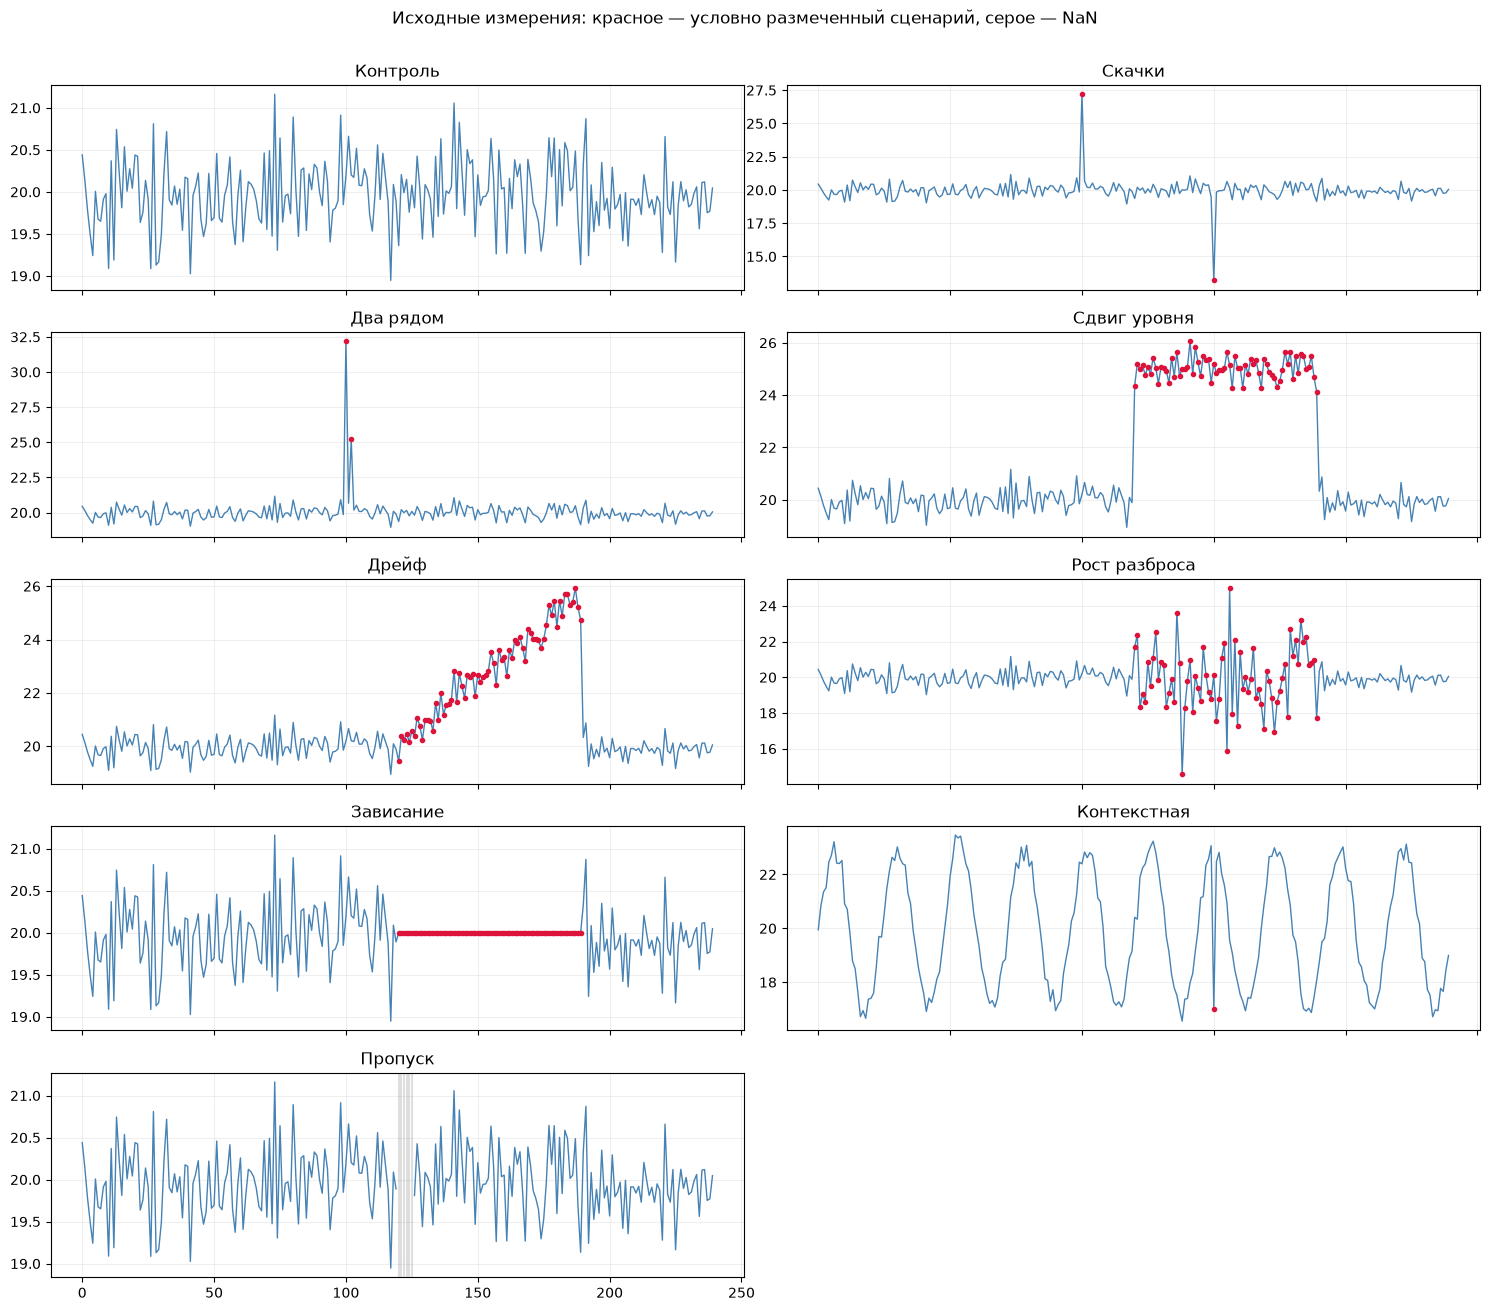

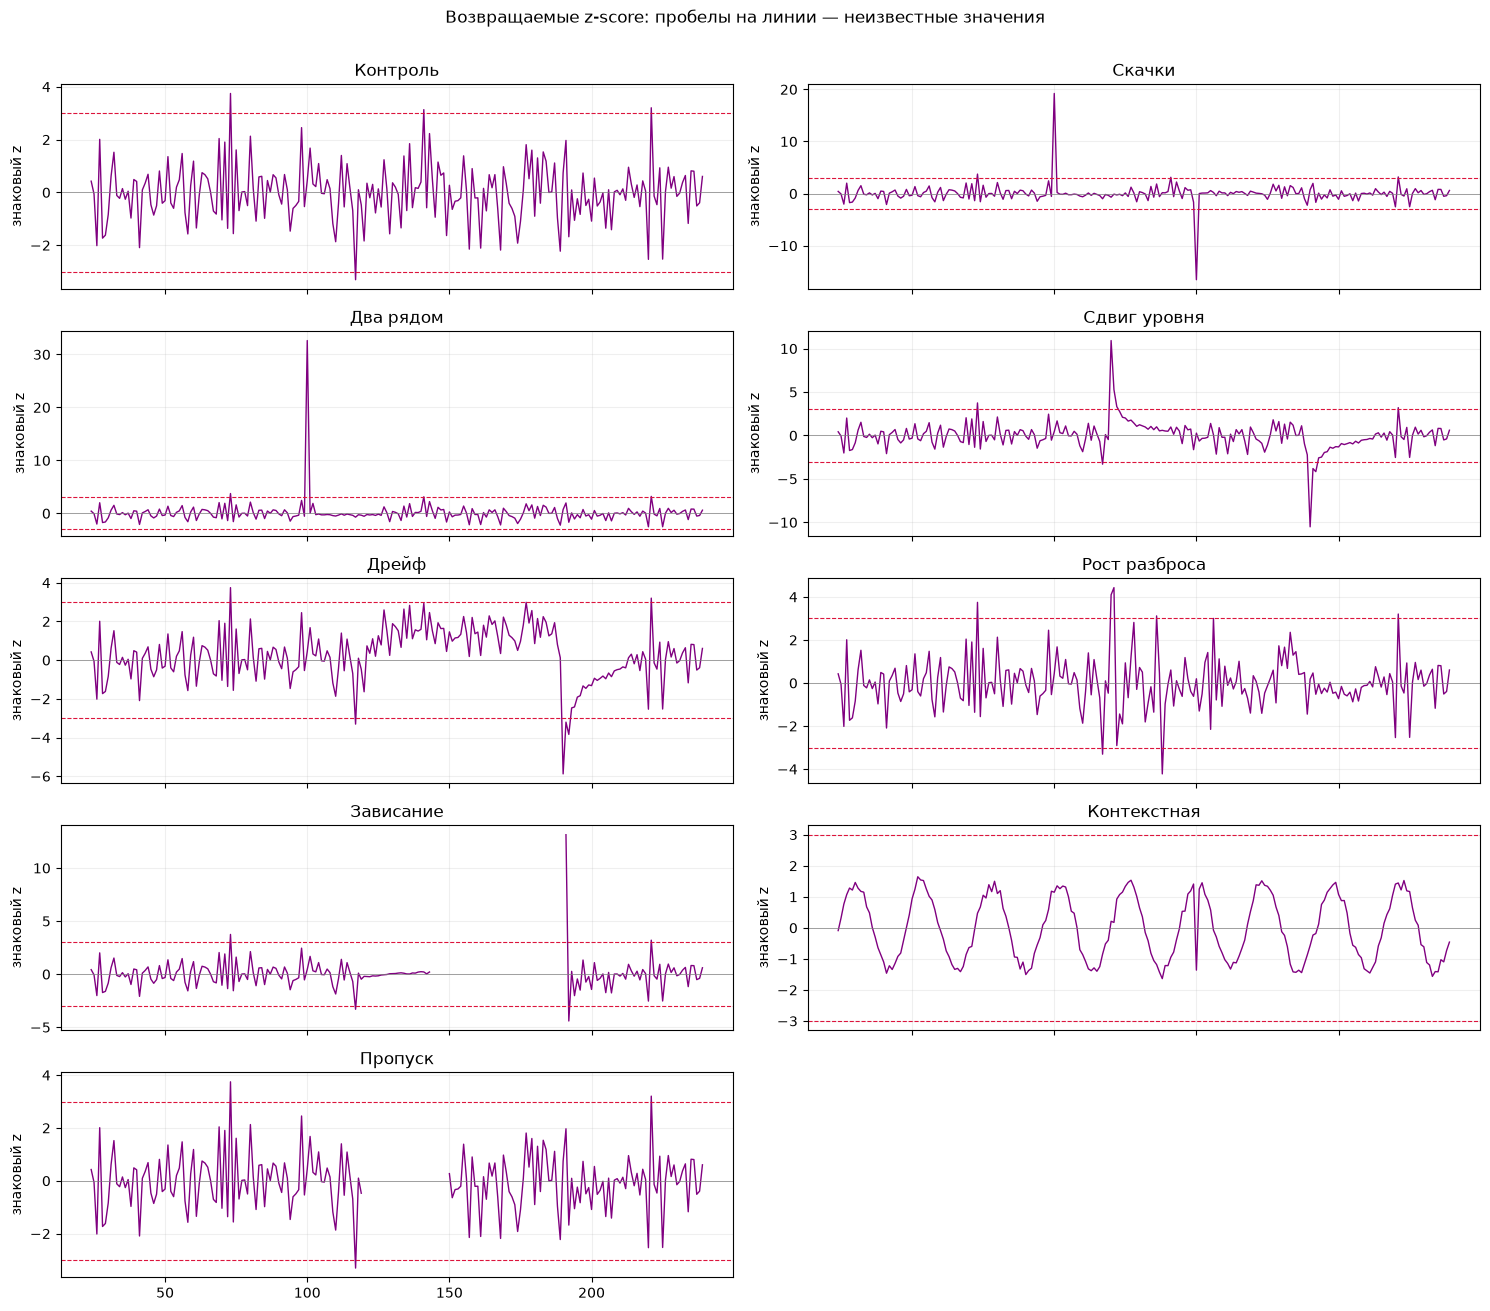

In [5]:
fig, axes = plt.subplots(5, 2, figsize=(15, 13), sharex=True)
for ax, (name, df) in zip(axes.flat, cases.items()):
    ax.plot(df.index, df.value, lw=1, color='steelblue')
    p = df.label.fillna(False).to_numpy(dtype=bool)
    ax.scatter(df.index[p], df.value[p], c='crimson', s=9, label='разметка', zorder=3)
    missing_idx = df.index[df.value.isna()]
    for x in missing_idx: ax.axvline(x, color='gray', alpha=.25)
    ax.set_title(name); ax.grid(alpha=.2)
axes.flat[-1].axis('off')
fig.suptitle('Исходные измерения: красное — условно размеченный сценарий, серое — NaN', y=1.005)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(5, 2, figsize=(15, 13), sharex=True)
for ax, (name, df) in zip(axes.flat, cases.items()):
    z = rolling_z_score(df.value, WINDOW)
    ax.plot(df.index, z, lw=1, color='purple')
    ax.axhline(THRESHOLD, ls='--', c='crimson', lw=.8)
    ax.axhline(-THRESHOLD, ls='--', c='crimson', lw=.8)
    ax.axhline(0, c='gray', lw=.5)
    ax.set_title(name); ax.set_ylabel('знаковый z'); ax.grid(alpha=.2)
axes.flat[-1].axis('off')
fig.suptitle('Возвращаемые z-score: пробелы на линии — неизвестные значения', y=1.005)
plt.tight_layout(); plt.show()

### Влияние выброса на последующее окно

Знаки z-score изолированных скачков соответствуют направлениям отклонений. При этом исходные измерения остаются в ряду и входят в следующие окна. Для анализа маскировки в двух рядах сравнивается одна и та же вторая точка: в одном предыдущий большой скачок отсутствует, в другом включён в историю.

In [6]:
control = cases['Два рядом'].value.copy()
without_first = control.copy(); without_first.iloc[100] -= 12
z_with = rolling_stats(control, 24); z_without = rolling_stats(without_first, 24)
contrast = pd.DataFrame([
    {'история': 'без первого скачка', 'вторая точка': without_first.iloc[102],
     'среднее': z_without.past_mean.iloc[102], 'σ': z_without.past_std.iloc[102], 'z': z_without.z_score.iloc[102]},
    {'история': 'первый скачок в окне', 'вторая точка': control.iloc[102],
     'среднее': z_with.past_mean.iloc[102], 'σ': z_with.past_std.iloc[102], 'z': z_with.z_score.iloc[102]},
])
display(contrast.round(3))
print('Сигнал второй точки при |z| > 3:', list(contrast.z.abs() > 3))

,история,вторая точка,среднее,σ,z
0,без первого скачка,25.201,20.078,0.385,13.322
1,первый скачок в окне,25.201,20.578,2.452,1.886


Сигнал второй точки при |z| > 3: [True, False]


Предыдущий скачок изменяет среднее и разброс окна. Увеличение разброса может уменьшить z-score следующей точки, даже если её значение не изменилось. Устойчивые статистики и исключение ранее обнаруженных скачков из истории представляют собой альтернативы, однако также требуют проверки.

### Пропуски и зависание датчика

После шести отсутствующих измерений строгий скользящий метод некоторое время не оценивает и поступившие затем данные. При зависании датчик продолжает передавать числа, но оценка может стать неопределённой, когда окно становится постоянным. Наряду с сигналом необходимо учитывать **доступность оценки**. Пропуски можно контролировать отдельно с помощью `value.isna()`; для зависания требуется предметно обоснованное правило.

In [7]:
for name in ['Пропуск', 'Зависание']:
    df = cases[name]
    stats = rolling_stats(df.value, WINDOW)
    print('---', name, ': строки 116–154; |z| > 3 — отдельная колонка')
    view = pd.DataFrame({'step': np.arange(116, 155),
                         'value': df.value.iloc[116:155].to_numpy(),
                         'past_std': stats.past_std.iloc[116:155].to_numpy(),
                         'z_score': stats.z_score.iloc[116:155].to_numpy(),
                         'signal': signal_from_z(stats.z_score).iloc[116:155].array})
    display(view.round(3))

--- Пропуск : строки 116–154; |z| > 3 — отдельная колонка


,step,value,past_std,z_score,signal
0,116,19.876,0.349,-0.688,False
1,117,18.947,0.348,-3.306,True
2,118,20.089,0.416,0.101,False
3,119,19.889,0.394,-0.472,False
4,120,NaN,0.392,NaN,<NA>
5,121,NaN,NaN,NaN,<NA>
6,122,NaN,NaN,NaN,<NA>
7,123,NaN,NaN,NaN,<NA>
8,124,NaN,NaN,NaN,<NA>
9,125,NaN,NaN,NaN,<NA>


--- Зависание : строки 116–154; |z| > 3 — отдельная колонка


,step,value,past_std,z_score,signal
0,116,19.876,0.349,-0.688,False
1,117,18.947,0.348,-3.306,True
2,118,20.089,0.416,0.101,False
3,119,19.889,0.394,-0.472,False
4,120,20.000,0.392,-0.204,False
5,121,20.000,0.388,-0.226,False
6,122,20.000,0.386,-0.239,False
7,123,20.000,0.346,-0.156,False
8,124,20.000,0.344,-0.176,False
9,125,20.000,0.343,-0.153,False


### Обнаружение длительного события

В сценариях сдвига, дрейфа, роста разброса и зависания интервал `[120,190)` условно рассматривается как одно событие. Для него определяется наличие хотя бы одного сигнала и задержка первого сигнала от начала интервала. Эта простая событийная метрика не группирует повторные тревоги, не учитывает предыдущие ложные сигналы и не оценивает определение конца события.

In [8]:
event_rows = []
for name in ['Сдвиг уровня', 'Дрейф', 'Рост разброса', 'Зависание']:
    _, stats, sig = evaluate_case(cases[name])
    hits = np.flatnonzero(sig.iloc[120:190].fillna(False).to_numpy(dtype=bool))
    event_rows.append({'сценарий': name, 'событие обнаружено': bool(len(hits)),
                       'задержка, шаги': int(hits[0]) if len(hits) else None,
                       'сигналов внутри 70 точек': int(sig.iloc[120:190].fillna(False).sum()),
                       'неопределено внутри': int(stats.z_score.iloc[120:190].isna().sum())})
display(pd.DataFrame(event_rows).set_index('сценарий'))

,событие обнаружено,"задержка, шаги",сигналов внутри 70 точек,неопределено внутри
сценарий,,,,
Сдвиг уровня,True,0.0,3,0
Дрейф,False,NaN,0,0
Рост разброса,True,0.0,5,0
Зависание,False,NaN,0,46


Если задача состоит в однократном оповещении оператора, ранний сигнал может быть полезен даже после адаптации окна. Для постоянного контроля неисправного состояния такой результат недостаточен. Медленный дрейф или умеренный рост разброса могут не вызвать резкого отклонения. Возврат к исходному режиму после искусственного сдвига также может выглядеть как аномалия.

### Контекстная аномалия

В сезонном сценарии значение в точке 150 типично для другой фазы цикла, но необычно для данного часа. Скользящее окно исходного ряда не учитывает время суток. Для сравнения из текущего значения вычитается значение 24 часа назад, после чего рассчитывается скользящий z-score остатков. Это упрощённый подход: измерение предыдущих суток также может быть ошибочным, а период — изменяться.

In [9]:
season = cases['Контекстная'].value
raw_z = rolling_z_score(season, 24)
residual = season - season.shift(24)
residual_z = rolling_z_score(residual, 24)
context_table = pd.DataFrame({'step': np.arange(147, 154),
                              'value': season.iloc[147:154].to_numpy(),
                              'score raw': raw_z.iloc[147:154].to_numpy(),
                              'score (value − value_24h_ago)': residual_z.iloc[147:154].to_numpy()})
display(context_table.round(3))
print('Сигнал в точке 150: по исходному ряду =', bool(abs(raw_z.iloc[150]) > 3),
      '; по сезонным остаткам =', bool(abs(residual_z.iloc[150]) > 3))

,step,value,score raw,score (value − value_24h_ago)
0,147,22.336,1.089,0.294
1,148,22.570,1.193,0.502
2,149,23.066,1.411,0.773
3,150,17.000,-1.362,-15.991
4,151,22.474,1.251,-0.402
5,152,22.818,1.453,0.240
6,153,22.018,1.079,0.101


Сигнал в точке 150: по исходному ряду = False ; по сезонным остаткам = True


## 6. Влияние окна и порога

Для разных размеров окна и порогов сравниваются ложные тревоги на контрольном ряду и обнаружение двух отдельных скачков. Эксперимент иллюстрирует компромисс, но не используется для выбора оптимальной настройки на тех же данных. Для настройки практического детектора необходимы отдельные прошлые данные и проверка на последующем тестовом периоде.

Увеличение порога при фиксированном score уменьшает или сохраняет число сигналов, но может приводить к пропуску слабых отклонений. Малое окно быстрее адаптируется и может сильнее реагировать на шум; большое дольше сохраняет сведения о предыдущем режиме. Эффект изменения окна зависит от ряда и не обязан быть монотонным.

In [10]:
sensitivity = []
for w in [6, 12, 24, 48]:
    for k in [2., 3., 4.]:
        r0, _, _ = evaluate_case(cases['Контроль'], w, k)
        r1, _, _ = evaluate_case(cases['Скачки'], w, k)
        sensitivity.append({'окно': w, 'порог': k,
                            'ложные тревоги на контроле': r0['FP'],
                            'найдено из 2 скачков': r1['TP'],
                            'покрытие контроля': r0['оценено']/N})
display(pd.DataFrame(sensitivity).round(3))

,окно,порог,ложные тревоги на контроле,найдено из 2 скачков,покрытие контроля
0,6,2.0,35,2,0.975
1,6,3.0,18,2,0.975
2,6,4.0,5,2,0.975
3,12,2.0,22,2,0.950
4,12,3.0,7,2,0.950
5,12,4.0,2,2,0.950
6,24,2.0,17,2,0.900
7,24,3.0,4,2,0.900
8,24,4.0,0,2,0.900
9,48,2.0,9,2,0.800


## 7. Сравнение с линейной регрессией

Скользящий z-score измеряет отклонение наблюдения относительно предыдущего окна. Линейная регрессия подбирает прогноз $\hat{x}_t=b_0+b_1t$, минимизируя сумму квадратов ошибок на обучающих данных. Удаление точек перед обучением регрессии — отдельная операция фильтрации, а не эквивалент z-score. Для обнаружения аномалий можно дополнительно анализировать остатки регрессионной модели.

В контролируемом примере линия тренда известна из способа генерации. В обучающую часть добавлены два скачка; подозрительные точки определяются скользящим z-score **без использования истинных меток**. Регрессии, обученные до и после фильтрации, сравниваются по ошибке на последующих измерениях. Первые 24 точки с неопределённым z-score сохраняются в обучающей выборке. Результат относится к данному примеру и не доказывает универсальной пользы удаления выбросов.

Фильтр удалил индексы train: [41, 50, 90]
Истинный наклон: 0.03


,наклон,MAE на будущих шумных измерениях
модель,,
Все train,0.0264,0.3555
После фильтрации train,0.0291,0.3010


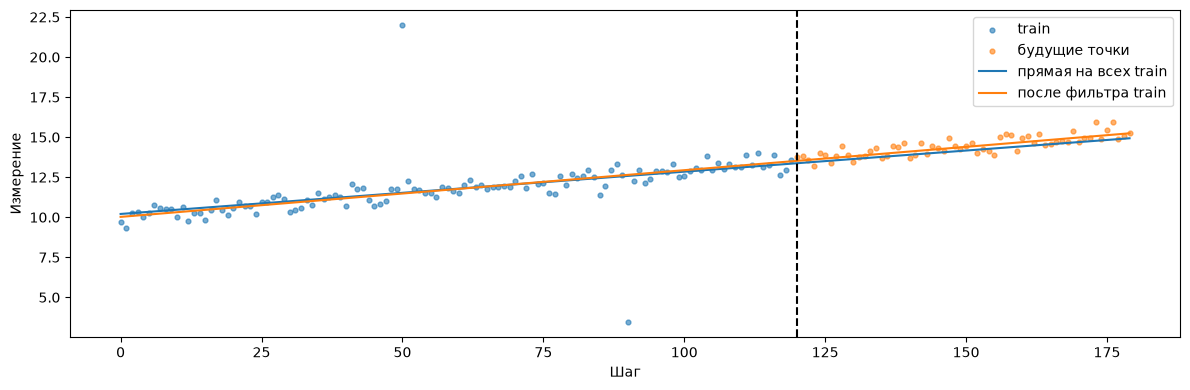

In [11]:
rng = np.random.default_rng(101)
t_reg = np.arange(180)
true_trend = 10 + 0.03*t_reg
reg_y = true_trend + rng.normal(0, .35, len(t_reg))
reg_y[[50, 90]] += [10, -9]
tr, te = slice(0, 120), slice(120, 180)
reg_scores = rolling_z_score(reg_y[:120], 24)
keep = ~signal_from_z(reg_scores, 3).fillna(False).to_numpy(dtype=bool)
x = t_reg.reshape(-1, 1)
full_model = LinearRegression().fit(x[tr], reg_y[tr])
filtered_model = LinearRegression().fit(x[tr][keep], reg_y[tr][keep])
print('Фильтр удалил индексы train:', np.flatnonzero(~keep).tolist())
print('Истинный наклон:', 0.03)
display(pd.DataFrame([
    {'модель': 'Все train', 'наклон': full_model.coef_[0],
     'MAE на будущих шумных измерениях': mean_absolute_error(reg_y[te], full_model.predict(x[te]))},
    {'модель': 'После фильтрации train', 'наклон': filtered_model.coef_[0],
     'MAE на будущих шумных измерениях': mean_absolute_error(reg_y[te], filtered_model.predict(x[te]))},
]).set_index('модель').round(4))
fig, ax = plt.subplots(figsize=(12, 4))
ax.scatter(t_reg[:120], reg_y[:120], s=12, alpha=.6, label='train')
ax.scatter(t_reg[120:], reg_y[120:], s=12, alpha=.6, label='будущие точки')
ax.plot(t_reg, full_model.predict(x), label='прямая на всех train')
ax.plot(t_reg, filtered_model.predict(x), label='после фильтра train')
ax.axvline(120, c='black', ls='--'); ax.set(xlabel='Шаг', ylabel='Измерение'); ax.legend()
plt.tight_layout(); plt.show()

## 8. Выводы и ограничения

Скользящий z-score является простым и интерпретируемым средством обнаружения отдельных сильных отклонений при относительно стабильных локальных статистиках. Сам расчёт не требует размеченных данных, однако для выбора порога и оценки качества необходимы разметка или другие проверенные критерии.

Эксперименты показывают ограничения метода при близко расположенных выбросах, длительных изменениях уровня, дрейфе, сезонности, пропусках и нулевом разбросе. Неопределённые оценки не следует считать нормальными наблюдениями. Смена режима может постепенно войти в окно и перестать вызывать сигнал; контекстная аномалия может не выделяться относительно общего локального распределения.

Перед практическим применением необходимо проверить временной шаг, единицы, дубликаты, пропуски и бесконечности; определить критерии событий; настроить параметры на прошлых данных и оценить их на будущем периоде. Помимо поточечных precision и recall следует учитывать долю неопределённых оценок, обнаружение событий и задержку. Порог `|z| > 3` не гарантирует заданной частоты ошибок на зависимых данных при оценке статистик по конечному окну.

**Ограничения исследования:** ряды синтетические, большинство сценариев имеют общий шумовой фон, а интервальная разметка условна. Для оценки применимости необходимы реальные размеченные ряды, независимый тестовый период и проверка различных режимов и длительностей событий.